**Validated reading copy.** Run the [source notebook](../../../../Tools/Evaluation_examples/Evaluation_and_Sensitivity.ipynb) in its original directory. This snapshot includes checked outputs; source SHA-256: `2263fe509487384784034f2a51a58e511887fb07eccc4ec7c005de21c3355737`. Timings describe this recorded environment, not a performance guarantee.

# Evaluating explanations: controlled cases, sensitivity, and failure

**Question:** when does an explanation help us inspect a model, and how much do the conclusions change with the evaluation choices?

This offline study uses six numerical features, independent and correlated synthetic data, three reproducible training runs, and cases sampled **before inspecting predictions**. It compares SHAP and LIME with random feature rankings, then changes the explainer settings and model. A final deliberately misleading shortcut model demonstrates why a mathematically correct explanation cannot certify a useful predictor.

Run from this folder with the repository's core dependencies. No datasets, weights, Java, GPU, or internet are needed. A typical CPU run takes a few minutes. The companion `evaluation_helpers.py` defines the metrics; the final cell writes JSON/CSV results under the ignored repository `validation/evaluation-study/` directory.

**What these experiments establish:** predictive quality, sensitivity to perturbations, repeatability, and dependence on specific choices. There is no universally correct attribution vector for real data, and no single score here measures “explanation quality.” Synthetic generating features provide a controlled reference for the *data-generating function*, not ground truth for what a fitted forest actually learned. Human usefulness requires a separate task-based evaluation.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import itertools
import json
import platform
import subprocess
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from lime.lime_tabular import LimeTabularExplainer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from evaluation_helpers import (
    array_digest, deletion_curves, grouped_permutation_auc,
    make_synthetic, signed_cosine, top_k_jaccard,
)

ROOT = Path.cwd().resolve().parents[1]
assert (ROOT / 'README.md').exists(), 'Run the notebook from Tools/Evaluation_examples/.'
OUTPUT = ROOT / 'validation' / 'evaluation-study'
OUTPUT.mkdir(parents=True, exist_ok=True)
FEATURES = ['x0_signal', 'x1_proxy_or_noise', 'x2_signal', 'x3_interaction', 'x4_noise', 'x5_noise']
SEEDS = [11, 22, 33]
SETTINGS = dict(n_samples=900, test_fraction=0.30, n_cases=12,
                forest_trees=64, forest_depth=5, forest_min_leaf=6,
                shap_background=32, lime_samples=1000, random_rankings=5,
                empirical_donors=8, permutation_repeats=8)
COLORS = {'SHAP': '#3465a4', 'LIME': '#b04b68', 'Random ranking': '#777777'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def fit_forest(X, y, seed):
    forest = RandomForestClassifier(
        n_estimators=SETTINGS['forest_trees'], max_depth=SETTINGS['forest_depth'],
        min_samples_leaf=SETTINGS['forest_min_leaf'], random_state=seed, n_jobs=1,
    )
    return forest.fit(X, y)

def shap_scores(model, cases, background):
    started = perf_counter()
    explainer = shap.TreeExplainer(model, data=background,
                                  feature_perturbation='interventional', model_output='probability')
    explanation = explainer(cases)
    values = explanation.values[:, :, 1]
    np.testing.assert_allclose(explanation.base_values[:, 1] + values.sum(axis=1),
                               model.predict_proba(cases)[:, 1], atol=1e-6)
    return values, perf_counter() - started

def lime_scores(model, cases, training, seed, n_samples=1000, kernel_width=None):
    started = perf_counter()
    kwargs = {} if kernel_width is None else {'kernel_width': kernel_width}
    explainer = LimeTabularExplainer(
        training, feature_names=FEATURES, class_names=['class 0', 'class 1'],
        discretize_continuous=False, random_state=seed, mode='classification', **kwargs,
    )
    values, fits, gaps = [], [], []
    for row in cases:
        explanation = explainer.explain_instance(
            row, model.predict_proba, labels=(1,), num_features=len(FEATURES), num_samples=n_samples,
        )
        attribution = np.zeros(len(FEATURES))
        for feature, weight in explanation.as_map()[1]:
            attribution[feature] = weight
        values.append(attribution)
        fits.append(explanation.score)
        gaps.append(abs(float(np.asarray(explanation.local_pred).ravel()[0]) - model.predict_proba(row[None])[0, 1]))
    return np.asarray(values), perf_counter() - started, np.asarray(fits), np.asarray(gaps)

/Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Define a controlled problem and a sampling protocol

The generating logit is $1.8x_0 + 1.1\sin(x_2) + 0.8x_2x_3 - 0.3$; labels are sampled from its logistic probability. In one setting all inputs are independent. In the other, $x_1$ has correlation 0.97 with $x_0$ but **no direct term in the generating logit**. It can nevertheless carry predictive information, and a forest can learn to use it. Crediting that proxy is not automatically an explainer error or a causal finding.

For each seed, the settings have the same labels and split indices; only the proxy relationship changes. Each run samples 12 held-out rows without using their true or predicted labels. We report the actual correct/incorrect case counts. Three runs are a small educational benchmark, not a population-level claim. Their variability combines changed data, split and model initialization.

In [2]:
runs, predictive_rows, manifests, local_diagnostics, timing_rows = {}, [], [], [], []
for scenario, correlated in [('Independent', False), ('Correlated proxy', True)]:
    for seed in SEEDS:
        X, y, generating_probability = make_synthetic(seed, correlated, SETTINGS['n_samples'])
        train_idx, test_idx = train_test_split(
            np.arange(len(y)), test_size=SETTINGS['test_fraction'], stratify=y, random_state=seed,
        )
        X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
        model = fit_forest(X_train, y_train, seed)
        probability = model.predict_proba(X_test)[:, 1]
        rng = np.random.default_rng(seed + 1000)
        positions = rng.choice(len(X_test), SETTINGS['n_cases'], replace=False)
        cases = X_test[positions]
        background_idx = rng.choice(len(X_train), SETTINGS['shap_background'], replace=False)
        background = X_train[background_idx]
        sv, shap_seconds = shap_scores(model, cases, background)
        lv, lime_seconds, local_r2, local_gap = lime_scores(
            model, cases, X_train, seed + 2000, SETTINGS['lime_samples'],
        )
        case_predictions = model.predict(cases)
        predictive_rows.append(dict(
            scenario=scenario, seed=seed, test_auc=roc_auc_score(y_test, probability),
            test_accuracy=accuracy_score(y_test, probability >= .5),
            explained_correct=int(np.sum(case_predictions == y_test[positions])),
            explained_incorrect=int(np.sum(case_predictions != y_test[positions])),
            explained_true_class_1=int(y_test[positions].sum()),
        ))
        run_id = f'{scenario}:{seed}'
        runs[run_id] = dict(scenario=scenario, seed=seed, model=model, X_train=X_train, y_train=y_train,
                            X_test=X_test, y_test=y_test, cases=cases, background=background,
                            scores={'SHAP': sv, 'LIME': lv}, positions=positions)
        manifests.append(dict(run_id=run_id, dataset_sha256=array_digest(X), labels_sha256=array_digest(y),
                              train_indices=train_idx.tolist(), test_indices=test_idx.tolist(),
                              explained_dataset_indices=test_idx[positions].tolist(),
                              shap_background_dataset_indices=train_idx[background_idx].tolist(),
                              model_parameters=model.get_params(),
                              case_sampling_seed=seed + 1000, lime_seed=seed + 2000))
        for method, elapsed in [('SHAP', shap_seconds), ('LIME', lime_seconds)]:
            timing_rows.append(dict(scenario=scenario, seed=seed, method=method,
                                   total_seconds=elapsed, seconds_per_case=elapsed / len(cases)))
        for i, (r2, gap) in enumerate(zip(local_r2, local_gap)):
            local_diagnostics.append(dict(scenario=scenario, seed=seed, case=i, lime_local_r2=r2,
                                          lime_probability_gap=gap))

predictive = pd.DataFrame(predictive_rows)
display(predictive.round(3))
display(pd.DataFrame(local_diagnostics).groupby('scenario')[['lime_local_r2', 'lime_probability_gap']].agg(['mean', 'min', 'max']).round(3))
print('SHAP probability additivity passed for every explained case. This is an accounting check, not a faithfulness score.')

,scenario,seed,test_auc,test_accuracy,explained_correct,explained_incorrect,explained_true_class_1
0,Independent,11,0.877,0.763,9,3,4
1,Independent,22,0.846,0.737,8,4,4
2,Independent,33,0.896,0.822,11,1,7
3,Correlated proxy,11,0.874,0.767,10,2,4
4,Correlated proxy,22,0.842,0.774,8,4,4
5,Correlated proxy,33,0.901,0.841,11,1,7


lime_local_r2               lime_probability_gap         \
                          mean    min    max                 mean    min   
scenario                                                                   
Correlated proxy         0.787  0.718  0.850                0.063  0.001   
Independent              0.796  0.707  0.875                0.072  0.001   

                         
                    max  
scenario                 
Correlated proxy  0.223  
Independent       0.225

SHAP probability additivity passed for every explained case. This is an accounting check, not a faithfulness score.


## 2. Removal tests: two replacement choices and a random control

For each case, rank features by **absolute** SHAP value, absolute LIME weight, or a random ordering. Replace the top $k$ features and measure $|f_1(x)-f_1(x_{\setminus k})|$, the absolute change in **class-1 probability**. The area under this curve uses fraction of features removed on the horizontal axis. Larger values mean earlier removal changed this model more under this protocol; they do not prove a better explanation, and opposite signed effects can cancel.

We use (a) the training mean vector and (b) eight randomly selected training rows as joint donors. Each donor supplies **all removed coordinates together**, but their dependence on retained coordinates is broken. Both strategies can create unrealistic inputs. The same donors are used for every method in a run. Five random rankings per case form the chance control; they are averaged within each run rather than counted as independent datasets. SHAP and LIME answer different questions, so their raw attribution magnitudes are never equated.

As a diagnostic, we also measure the mean standardized nearest-training-row distance of perturbed inputs. It is a descriptive distance, **not a calibrated out-of-distribution probability**. The curves start at zero and share an endpoint for a given donor strategy because all features are eventually replaced.

mean  \
scenario         baseline               method                  
Correlated proxy Empirical joint donors LIME            0.265   
                                        Random ranking  0.179   
                                        SHAP            0.255   
                 Training mean          LIME            0.197   
                                        Random ranking  0.134   
                                        SHAP            0.206   
Independent      Empirical joint donors LIME            0.254   
                                        Random ranking  0.164   
                                        SHAP            0.256   
                 Training mean          LIME            0.195   
                                        Random ranking  0.131   
                                        SHAP            0.198   

                                                        SD across 3 run means  
scenario         baseline               method                                 
Correlated proxy Empirical joint donors LIME                            0.027  
                                        Random ranking                  0.015  
                                        SHAP                            0.030  
                 Training mean          LIME                            0.022  
                                        Random ranking                  0.017  
                                        SHAP                            0.039  
Independent      Empirical joint donors LIME                            0.028  
                                        Random ranking                  0.003  
                                        SHAP                            0.026  
                 Training mean          LIME                            0.031  
                                        Random ranking                  0.016  
                                        SHAP                            0.042

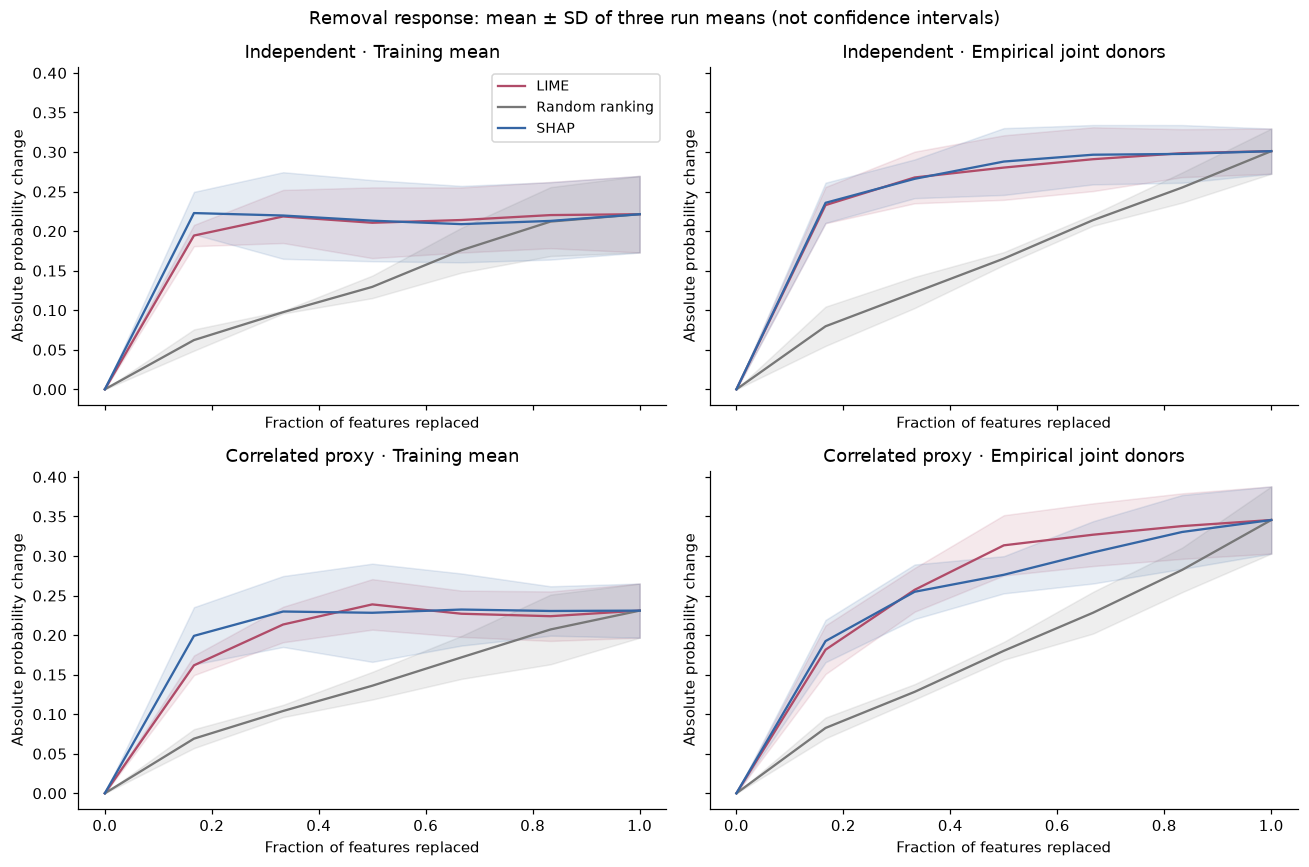

In [3]:
removal_rows, distance_rows = [], []
for run_id, run in runs.items():
    cases, training, model = run['cases'], run['X_train'], run['model']
    rng = np.random.default_rng(run['seed'] + 3000)
    donor_indices = rng.choice(len(training), SETTINGS['empirical_donors'], replace=False)
    donors_by_name = {'Training mean': training.mean(axis=0, keepdims=True),
                      'Empirical joint donors': training[donor_indices]}
    for manifest in manifests:
        if manifest['run_id'] == run_id:
            manifest['deletion_seed'] = run['seed'] + 3000
            manifest['empirical_donor_training_positions'] = donor_indices.tolist()
    methods = [(name, 0, scores) for name, scores in run['scores'].items()]
    methods += [('Random ranking', repeat, rng.random(cases.shape))
                for repeat in range(SETTINGS['random_rankings'])]
    scale = training.std(axis=0)
    reference_neighbors = NearestNeighbors(n_neighbors=1).fit(training / scale)
    for baseline, donors in donors_by_name.items():
        for method, repeat, scores in methods:
            curve, area, changed = deletion_curves(lambda rows: model.predict_proba(rows)[:, 1], cases, scores, donors)
            np.testing.assert_allclose(curve[:, 0], 0, atol=1e-12)
            for case in range(len(cases)):
                for k in range(len(FEATURES) + 1):
                    removal_rows.append(dict(scenario=run['scenario'], seed=run['seed'], case=case,
                                             baseline=baseline, method=method, random_repeat=repeat,
                                             removed=k, probability_change=curve[case, k], removal_area=area[case]))
            distance = reference_neighbors.kneighbors(changed.reshape(-1, len(FEATURES)) / scale,
                                                       return_distance=True)[0].reshape(changed.shape[:3])
            for k, mean_distance in enumerate(distance.mean(axis=(1, 2))):
                distance_rows.append(dict(scenario=run['scenario'], seed=run['seed'], baseline=baseline,
                                          method=method, random_repeat=repeat, removed=k,
                                          standardized_neighbor_distance=mean_distance))

removal = pd.DataFrame(removal_rows)
# Average cases and random repetitions within a run; then summarize the three run means.
run_curves = removal.groupby(['scenario', 'seed', 'baseline', 'method', 'removed'], as_index=False)['probability_change'].mean()
run_areas = removal[removal.removed == 0].groupby(['scenario', 'seed', 'baseline', 'method'], as_index=False)['removal_area'].mean()
area_summary = run_areas.groupby(['scenario', 'baseline', 'method'])['removal_area'].agg(['mean', 'std'])
display(area_summary.rename(columns={'std': 'SD across 3 run means'}).round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for row, scenario in enumerate(['Independent', 'Correlated proxy']):
    for col, baseline in enumerate(donors_by_name):
        ax = axes[row, col]
        data = run_curves[(run_curves.scenario == scenario) & (run_curves.baseline == baseline)]
        for method, group in data.groupby('method'):
            summary = group.groupby('removed').probability_change.agg(['mean', 'std'])
            x = summary.index.to_numpy() / len(FEATURES)
            ax.plot(x, summary['mean'], label=method, color=COLORS[method])
            ax.fill_between(x, summary['mean'] - summary['std'], summary['mean'] + summary['std'],
                            color=COLORS[method], alpha=.12)
        ax.set(title=f'{scenario} · {baseline}', xlabel='Fraction of features replaced', ylabel='Absolute probability change')
axes[0, 0].legend(fontsize=9)
fig.suptitle('Removal response: mean ± SD of three run means (not confidence intervals)')
plt.tight_layout()
fig.savefig(OUTPUT / 'removal_curves.png', bbox_inches='tight')
plt.show()

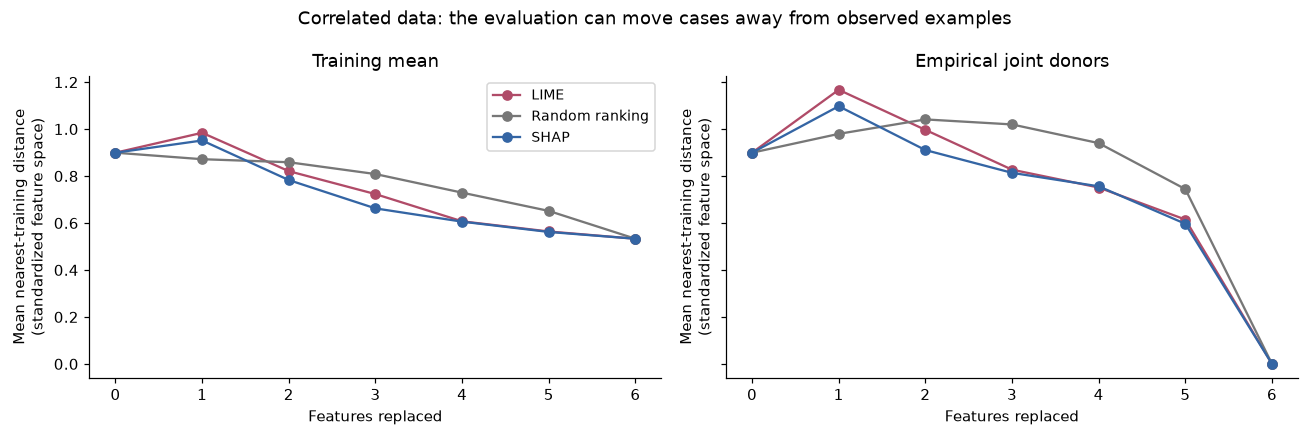

In [4]:
distances = pd.DataFrame(distance_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, baseline in zip(axes, donors_by_name):
    selected = distances[(distances.scenario == 'Correlated proxy') & (distances.baseline == baseline)]
    for method, group in selected.groupby('method'):
        summary = group.groupby('removed').standardized_neighbor_distance.mean()
        ax.plot(summary.index, summary, marker='o', color=COLORS[method], label=method)
    ax.set(title=baseline, xlabel='Features replaced', ylabel='Mean nearest-training distance\n(standardized feature space)')
axes[0].legend(fontsize=9)
fig.suptitle('Correlated data: the evaluation can move cases away from observed examples')
plt.tight_layout()
fig.savefig(OUTPUT / 'replacement_distance.png', bbox_inches='tight')
plt.show()

## 3. Correlation and grouped permutation

Individual permutation breaks both feature–target associations and dependencies between inputs. Correlated features may substitute for each other in a fitted model. Jointly permuting $x_0$ and $x_1$ using one row shuffle preserves their internal relationship while breaking their relationship with the remaining features and labels. The group score is **not** generally the sum of the individual scores.

We measure held-out **ROC AUC decrease**, not attribution magnitude. Repeated shuffles describe Monte Carlo variation conditional on this fitted model and test set. The chart shows the three run means separately, so shuffle repetitions are not mistaken for independent training runs.

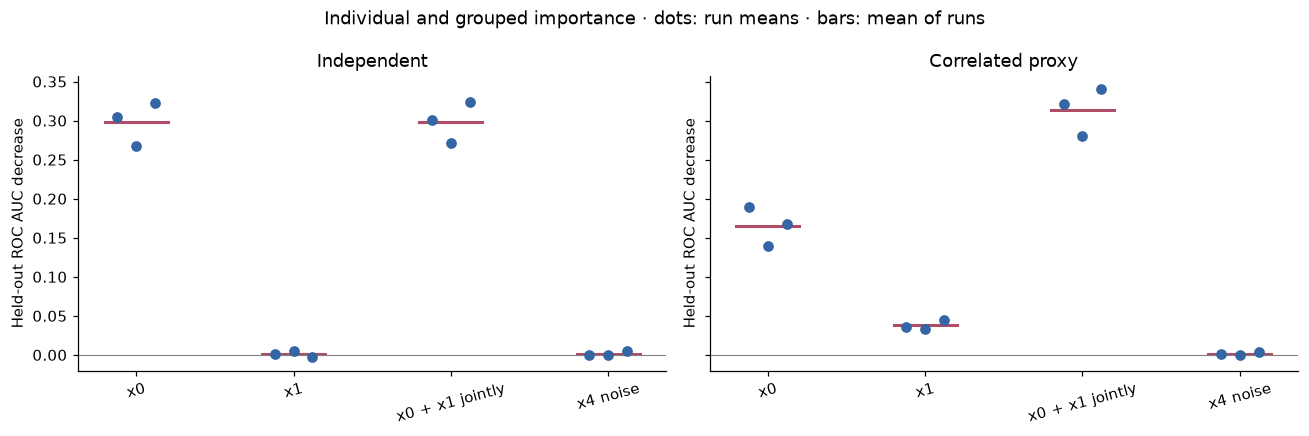

mean  shuffle SD
scenario         seed group                             
Correlated proxy 11   x0               0.189       0.021
                      x0 + x1 jointly  0.321       0.023
                      x1               0.036       0.010
                      x4 noise         0.001       0.003
                 22   x0               0.139       0.023
                      x0 + x1 jointly  0.280       0.027
                      x1               0.033       0.013
                      x4 noise         0.001       0.002
                 33   x0               0.167       0.021
                      x0 + x1 jointly  0.340       0.033
                      x1               0.045       0.008
                      x4 noise         0.003       0.002
Independent      11   x0               0.304       0.025
                      x0 + x1 jointly  0.300       0.025
                      x1               0.001       0.001
                      x4 noise        -0.000       0.002
                 22   x0               0.267       0.028
                      x0 + x1 jointly  0.271       0.027
                      x1               0.005       0.004
                      x4 noise        -0.001       0.002
                 33   x0               0.323       0.032
                      x0 + x1 jointly  0.324       0.028
                      x1              -0.003       0.003
                      x4 noise         0.005       0.003

In [5]:
permutation_rows = []
groups = {'x0': [0], 'x1': [1], 'x0 + x1 jointly': [0, 1], 'x4 noise': [4]}
for run in runs.values():
    values = grouped_permutation_auc(run['model'], run['X_test'], run['y_test'], groups,
                                     seed=run['seed'] + 4000, n_repeats=SETTINGS['permutation_repeats'])
    for group, differences in values.items():
        for repeat, decrease in enumerate(differences):
            permutation_rows.append(dict(scenario=run['scenario'], seed=run['seed'], group=group,
                                         shuffle=repeat, auc_decrease=decrease))
permutation = pd.DataFrame(permutation_rows)
permutation_runs = permutation.groupby(['scenario', 'seed', 'group']).auc_decrease.mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, scenario in zip(axes, ['Independent', 'Correlated proxy']):
    subset = permutation_runs[permutation_runs.scenario == scenario]
    for i, group in enumerate(groups):
        points = subset[subset.group == group].auc_decrease.to_numpy()
        ax.scatter(i + np.linspace(-.12, .12, len(points)), points, color='#3465a4', zorder=3)
        ax.plot([i - .2, i + .2], [points.mean()] * 2, color='#b04b68', lw=2)
    ax.axhline(0, color='gray', lw=.7)
    ax.set(xticks=range(len(groups)), xticklabels=groups, title=scenario, ylabel='Held-out ROC AUC decrease')
    ax.tick_params(axis='x', rotation=15)
fig.suptitle('Individual and grouped importance · dots: run means · bars: mean of runs')
plt.tight_layout()
fig.savefig(OUTPUT / 'grouped_permutation.png', bbox_inches='tight')
plt.show()
display(permutation.groupby(['scenario', 'seed', 'group']).auc_decrease.agg(['mean', 'std']).rename(columns={'std': 'shuffle SD'}).round(3))

## 4. Sensitivity to settings, sampling, and model changes

Freeze the **correlated-data seed-11 split, forest, six first sampled cases, class 1 and preprocessing**. These six cases are a computational subset of the prespecified sample, not selected by explanation quality. Compare configurations **within the same method** using top-three absolute-score Jaccard overlap (0–1) and signed cosine (−1–1). A zero attribution vector makes similarity undefined and is recorded as missing, never perfect. Stable explanations can still be wrong; instability can reflect real changes in the model.

- SHAP: backgrounds of 8, 32 and 96 training rows, each with three sample seeds, compared with a fixed 96-row reference. This changes a defined reference distribution; it is not only numerical error.
- LIME: 300 versus 1,200 perturbations and three kernel widths (0.5, 0.75, 1.5 × √features), each with three seeds, compared with a 3,000-perturbation reference. We use continuous features without discretization, and rank local standardized-feature weights only within this LIME setup.
- Model changes: refit the same forest on identical training data with three different model seeds, keeping SHAP's background fixed. Also fit forests to shuffled training labels. Label randomization is a dependence sanity check, not a guarantee of faithfulness.

The following tables retain every configuration and seed. The plots show configuration means across sampled cases for each replicate; they are descriptive, not significance tests.

In [6]:
fixed = runs['Correlated proxy:11']
fixed_cases = fixed['cases'][:6]
training, target, fixed_model = fixed['X_train'], fixed['y_train'], fixed['model']
reference_rng = np.random.default_rng(987)
reference_background = training[reference_rng.choice(len(training), 96, replace=False)]
reference_shap, _ = shap_scores(fixed_model, fixed_cases, reference_background)
reference_lime, _, _, _ = lime_scores(fixed_model, fixed_cases, training, 987, n_samples=3000)
sensitivity_rows, sensitivity_runtime, model_change_rows = [], [], []

def record_similarity(experiment, configuration, seed, scores, reference, seconds):
    overlap = top_k_jaccard(scores, reference, k=3)
    cosine = signed_cosine(scores, reference)
    for case, (jaccard, cos) in enumerate(zip(overlap, cosine)):
        sensitivity_rows.append(dict(experiment=experiment, configuration=configuration,
                                     seed=seed, case=case, top3_jaccard=jaccard, signed_cosine=cos))
    sensitivity_runtime.append(dict(experiment=experiment, configuration=configuration,
                                    seed=seed, cases=len(scores), seconds=seconds))

for size in [8, 32, 96]:
    for seed in [21, 22, 23]:
        rng = np.random.default_rng(seed)
        background = training[rng.choice(len(training), size, replace=False)]
        scores, seconds = shap_scores(fixed_model, fixed_cases, background)
        record_similarity('SHAP background', f'{size} rows', seed, scores, reference_shap, seconds)

for samples in [300, 1200]:
    for width in [.5, .75, 1.5]:
        for seed in [21, 22, 23]:
            scores, seconds, _, _ = lime_scores(fixed_model, fixed_cases, training, seed, samples,
                                                kernel_width=width * np.sqrt(len(FEATURES)))
            record_similarity('LIME settings', f'n={samples}; width={width}√d', seed, scores, reference_lime, seconds)

for randomize_labels in [False, True]:
    for seed in [21, 22, 23]:
        label = 'Shuffled labels' if randomize_labels else 'Forest seed'
        fit_target = np.random.default_rng(seed).permutation(target) if randomize_labels else target
        altered = fit_forest(training, fit_target, seed)
        scores, seconds = shap_scores(altered, fixed_cases, reference_background)
        record_similarity('Model change', label, seed, scores, reference_shap, seconds)
        altered_probability = altered.predict_proba(fixed['X_test'])[:, 1]
        model_change_rows.append(dict(configuration=label, seed=seed,
                                     heldout_auc=roc_auc_score(fixed['y_test'], altered_probability),
                                     mean_probability_change=np.abs(altered_probability - fixed_model.predict_proba(fixed['X_test'])[:, 1]).mean()))

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity_run_means = sensitivity.groupby(['experiment', 'configuration', 'seed'], as_index=False)[['top3_jaccard', 'signed_cosine']].mean()
display(sensitivity_run_means.groupby(['experiment', 'configuration'])[['top3_jaccard', 'signed_cosine']].agg(['mean', 'min', 'max']).round(3))
display(pd.DataFrame(model_change_rows).round(3))

top3_jaccard               signed_cosine  \
                                             mean    min    max          mean   
experiment      configuration                                                   
LIME settings   n=1200; width=0.5√d         0.917  0.917  0.917         0.994   
                n=1200; width=0.75√d        1.000  1.000  1.000         0.999   
                n=1200; width=1.5√d         1.000  1.000  1.000         0.997   
                n=300; width=0.5√d          0.917  0.917  0.917         0.985   
                n=300; width=0.75√d         0.972  0.917  1.000         0.996   
                n=300; width=1.5√d          1.000  1.000  1.000         0.995   
Model change    Forest seed                 0.900  0.833  1.000         0.995   
                Shuffled labels             0.344  0.317  0.400         0.203   
SHAP background 32 rows                     0.944  0.917  1.000         0.990   
                8 rows                      0.778  0.667  0.833         0.982   
                96 rows                     0.917  0.917  0.917         0.996   

                                                    
                                        min    max  
experiment      configuration                       
LIME settings   n=1200; width=0.5√d   0.993  0.995  
                n=1200; width=0.75√d  0.999  0.999  
                n=1200; width=1.5√d   0.997  0.998  
                n=300; width=0.5√d    0.983  0.986  
                n=300; width=0.75√d   0.995  0.996  
                n=300; width=1.5√d    0.994  0.997  
Model change    Forest seed           0.992  0.997  
                Shuffled labels      -0.053  0.348  
SHAP background 32 rows               0.980  0.998  
                8 rows                0.976  0.987  
                96 rows               0.991  0.999

,configuration,seed,heldout_auc,mean_probability_change
0,Forest seed,21,0.875,0.028
1,Forest seed,22,0.880,0.031
2,Forest seed,23,0.876,0.026
3,Shuffled labels,21,0.428,0.251
4,Shuffled labels,22,0.620,0.226
5,Shuffled labels,23,0.377,0.253


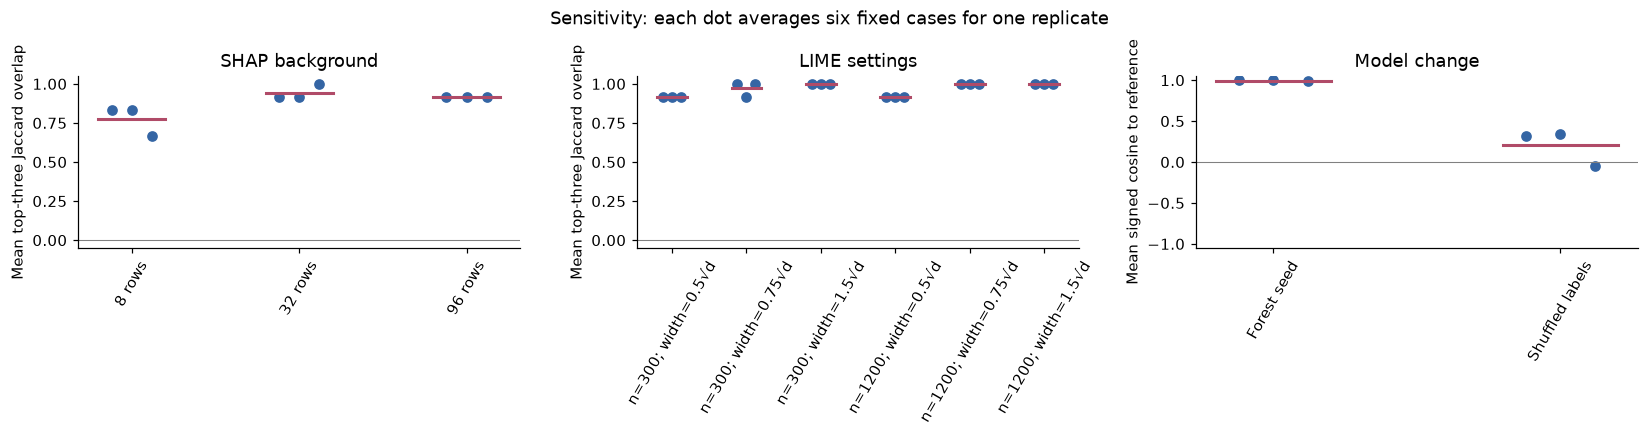

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, experiment in zip(axes, ['SHAP background', 'LIME settings', 'Model change']):
    data = sensitivity_run_means[sensitivity_run_means.experiment == experiment]
    names = ({'SHAP background': ['8 rows', '32 rows', '96 rows'],
              'LIME settings': [f'n={n}; width={w}√d' for n in [300, 1200] for w in [.5, .75, 1.5]],
              'Model change': ['Forest seed', 'Shuffled labels']}[experiment])
    metric = 'signed_cosine' if experiment == 'Model change' else 'top3_jaccard'
    for i, name in enumerate(names):
        values = data.loc[data.configuration == name, metric].to_numpy()
        ax.scatter(i + np.linspace(-.12, .12, len(values)), values, color='#3465a4')
        ax.plot([i - .2, i + .2], [values.mean()] * 2, color='#b04b68', lw=2)
    ax.set(title=experiment, xticks=range(len(names)), xticklabels=names,
           ylim=(-1.05, 1.05) if metric == 'signed_cosine' else (-.05, 1.05),
           ylabel='Mean signed cosine to reference' if metric == 'signed_cosine' else 'Mean top-three Jaccard overlap')
    ax.tick_params(axis='x', rotation=60)
    ax.axhline(0, color='gray', lw=.7)
fig.suptitle('Sensitivity: each dot averages six fixed cases for one replicate')
plt.tight_layout()
fig.savefig(OUTPUT / 'sensitivity.png', bbox_inches='tight')
plt.show()

## 5. A failure case: a faithful explanation of a bad shortcut

Create a training-only shortcut: feature $x_1$ nearly reveals the sampled label. At deployment, that feature becomes independent noise. The other generating relationship remains unchanged. A forest can exploit the shortcut and generalize poorly. SHAP can correctly attribute its decisions to $x_1$ and still pass additivity.

This construction demonstrates **why explanation validity is distinct from predictive reliability**. It does not imply that every feature correlated with a label is illegitimate. The failure comes from an explicit change in the feature–label relationship between training and test.

,training_auc,shifted_test_auc,largest_mean_absolute_shap_feature,additivity_check
0,1.0,0.693329,x1_proxy_or_noise,passed for all 40 prespecified test rows


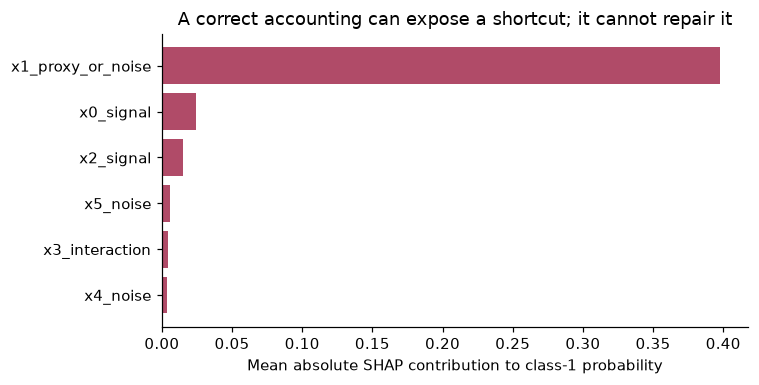

In [8]:
shortcut_rng = np.random.default_rng(4321)
shortcut_train, shortcut_y_train, _ = make_synthetic(seed=4321, n_samples=700)
shortcut_test, shortcut_y_test, _ = make_synthetic(seed=5432, n_samples=300)
shortcut_train[:, 1] = 2 * shortcut_y_train - 1 + shortcut_rng.normal(0, .05, len(shortcut_y_train))
shortcut_test[:, 1] = shortcut_rng.choice([-1., 1.], len(shortcut_y_test)) + shortcut_rng.normal(0, .05, len(shortcut_y_test))
shortcut_model = fit_forest(shortcut_train, shortcut_y_train, 4321)
shortcut_background = shortcut_train[shortcut_rng.choice(len(shortcut_train), 64, replace=False)]
shortcut_values, _ = shap_scores(shortcut_model, shortcut_test[:40], shortcut_background)
shortcut_metrics = dict(training_auc=roc_auc_score(shortcut_y_train, shortcut_model.predict_proba(shortcut_train)[:, 1]),
                        shifted_test_auc=roc_auc_score(shortcut_y_test, shortcut_model.predict_proba(shortcut_test)[:, 1]),
                        largest_mean_absolute_shap_feature=FEATURES[int(np.argmax(np.abs(shortcut_values).mean(axis=0)))],
                        additivity_check='passed for all 40 prespecified test rows')
display(pd.DataFrame([shortcut_metrics]))
fig, ax = plt.subplots(figsize=(7, 3.6))
mean_absolute = np.abs(shortcut_values).mean(axis=0)
order = np.argsort(mean_absolute)
ax.barh(np.asarray(FEATURES)[order], mean_absolute[order], color='#b04b68')
ax.set(xlabel='Mean absolute SHAP contribution to class-1 probability',
       title='A correct accounting can expose a shortcut; it cannot repair it')
plt.tight_layout()
fig.savefig(OUTPUT / 'shortcut_failure.png', bbox_inches='tight')
plt.show()

## 6. Cost and an audit trail

Timing includes explainer construction and explanation calls, excludes model training, and is measured on this machine without warm-up correction. Per-case values amortize setup; they are not service latency guarantees. Comparisons depend on budgets: exact tree computations and a 1,000-sample LIME approximation do different work. Treat runtimes as observed costs alongside the diagnostics, not a universal speed ranking.

The saved JSON contains source hashes, dataset fingerprints, split/case/background indices, seeds, settings, environment and per-run records. CSVs retain case-level metrics and perturbation repetitions. Output files are generated in `validation/`, which Git ignores; archive a chosen validated result with its manifest for a durable research release. No serialized model or third-party data is downloaded.

In [9]:
timing = pd.DataFrame(timing_rows)
display(timing.groupby(['scenario', 'method'])[['total_seconds', 'seconds_per_case']].agg(['mean', 'min', 'max']).round(4))
tables = dict(predictive_quality=predictive, removal=removal, replacement_distance=distances,
              grouped_permutation=permutation, sensitivity=sensitivity,
              local_diagnostics=pd.DataFrame(local_diagnostics), runtime=timing,
              sensitivity_runtime=pd.DataFrame(sensitivity_runtime), model_changes=pd.DataFrame(model_change_rows))
for name, table in tables.items():
    table.to_csv(OUTPUT / f'{name}.csv', index=False)
try:
    commit = subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip()
    git_dirty = bool(subprocess.check_output(['git', 'status', '--porcelain'], cwd=ROOT, text=True).strip())
except (OSError, subprocess.CalledProcessError):
    commit = None
    git_dirty = None
source_hashes = {}
for filename in ['Evaluation_and_Sensitivity.ipynb', 'evaluation_helpers.py']:
    path = Path(filename)
    if path.exists():
        source_hashes[filename] = hashlib.sha256(path.read_bytes()).hexdigest()
report = dict(
    schema_version=1, study='Synthetic XAI evaluation and sensitivity', git_commit=commit, git_dirty=git_dirty,
    source_sha256=source_hashes, settings=SETTINGS, seeds=SEEDS, features=FEATURES,
    environment=dict(python=sys.version, platform=platform.platform(), machine=platform.machine(),
                     packages={name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'shap', 'lime', 'matplotlib']}),
    generating_process=dict(logit='1.8*x0 + 1.1*sin(x2) + 0.8*x2*x3 - 0.3', proxy_correlation=.97,
                            direct_inputs=[0, 2, 3], label_sampling='Bernoulli(logistic(logit))'),
    sensitivity_settings=dict(fixed_run='Correlated proxy:11', first_sampled_cases=6,
                              replicate_seeds=[21, 22, 23], reference_seed=987, reference_background_size=96,
                              shap_background_sizes=[8, 32, 96], lime_samples=[300, 1200],
                              lime_width_multipliers=[.5, .75, 1.5], lime_reference_samples=3000),
    manifests=manifests, shortcut=dict(settings={'training_seed':4321, 'test_seed':5432, 'training_rows':700, 'test_rows':300}, results=shortcut_metrics),
    metric_units=dict(test_auc='ROC AUC', probability_change='class-1 probability',
                      removal_area='class-1 probability × fraction of features removed',
                      auc_decrease='ROC AUC decrease', top3_jaccard='fraction', signed_cosine='unitless [-1, 1]',
                      standardized_neighbor_distance='Euclidean distance after division by training feature SD'),
    interpretation='Three-run SD is descriptive; no confidence intervals or universal method winner are claimed.',
    tables={name: json.loads(table.to_json(orient='records')) for name, table in tables.items()},
)
(OUTPUT / 'results.json').write_text(json.dumps(report, indent=2, allow_nan=False) + '\n')
print(f'Wrote results, metadata, CSVs and figures to {OUTPUT}')

total_seconds                 seconds_per_case  \
                                 mean     min     max             mean   
scenario         method                                                  
Correlated proxy LIME          0.1697  0.1694  0.1699           0.0141   
                 SHAP          0.0091  0.0087  0.0095           0.0008   
Independent      LIME          0.1697  0.1697  0.1699           0.0141   
                 SHAP          0.0088  0.0086  0.0091           0.0007   

                                         
                            min     max  
scenario         method                  
Correlated proxy LIME    0.0141  0.0142  
                 SHAP    0.0007  0.0008  
Independent      LIME    0.0141  0.0142  
                 SHAP    0.0007  0.0008

Wrote results, metadata, CSVs and figures to /Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/validation/evaluation-study


## Reading the findings responsibly

- First inspect held-out prediction performance. Explain mistakes as well as successful predictions; the sample protocol and observed counts are recorded above.
- Compare removal curves under **both** replacements and the random control. A different conclusion across replacements is a finding about evaluation sensitivity, not permission to choose a favorable score.
- Grouped and individual feature importance answer different questions. A proxy can matter to the fitted model without directly entering the generating equation.
- Backgrounds, neighborhoods and model retraining can change explanations. Report these choices and variability. Top-$k$ overlap ignores signs; signed cosine complements it but can be dominated by a large coordinate.
- Additivity and local fit are useful checks, but neither establishes causality, generalization, robustness, or usefulness to a person. A model can have an excellent explanation of an undesirable shortcut.
- Further work should add a larger prespecified multi-dataset benchmark, uncertainty from independent data samples, domain-valid interventions, retraining-based evaluation, and human task outcomes. This compact study supplies a reproducible foundation, not a field-wide leaderboard.

## Primary references and implementation documentation

1. [Doshi-Velez & Kim — Towards a Rigorous Science of Interpretable Machine Learning](https://arxiv.org/abs/1702.08608): distinguish application-grounded, human-grounded and functionally grounded evaluation.
2. [Adebayo et al. — Sanity Checks for Saliency Maps](https://papers.nips.cc/paper/2018/file/294a8ed24b1ad22ec2e7efea049b8737-Paper.pdf): randomization checks for dependence on a learned model. Our shuffled-label forest experiment adapts the idea; it is not a replication of their neural saliency study.
3. [Hedström et al. — Quantus](https://jmlr.org/papers/v24/22-0142.html): evaluation metrics and sensitivity to evaluation choices. This notebook uses explicit small helpers rather than adding that dependency.
4. [Hooker et al. — A Benchmark for Interpretability Methods in Deep Neural Networks](https://arxiv.org/abs/1806.10758): removing features can introduce distribution changes; retraining evaluations address a different question and incur extra cost.
5. [Aas et al. — Explaining Individual Predictions When Features Are Dependent](https://arxiv.org/abs/1903.10464): assumptions about dependence change the explanatory question.
6. [Krishna et al. — The Disagreement Problem in Explainable Machine Learning](https://arxiv.org/abs/2202.01602): disagreement between explanations and practitioner interpretation.
7. [SHAP TreeExplainer documentation](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html) and [LIME documentation](https://lime-ml.readthedocs.io/en/latest/lime.html): actual implementation parameters used here.